<div align="center">
    <b><font size="7">Group 6: Phase 3</font></b>
    <br>
    <b><font size="5">Aaron Timbang, Sergio Fernandez Donneys</font></b>
</div>

In [3]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Part 0: What Changed from Phase 2

1\. Yes, the research question was modified.

> **Phase 2:** Can a game's genre and platform be used to predict its North American sales, among VGChartz-tracked titles released through 2024 on platforms with at least 100 tracked titles?

> **Phase 3:** Can a game's genre and platform be used to predict its North American sales, among VGChartz-tracked titles released through 2020 on platforms with at least 100 tracked titles?

2\. Yes, the dataset was modified.

3\. Code to further cleaning the data set.

In [17]:
# Load Phase 2 dataset
df = pd.read_csv("../Phase 2/phase2_working.csv")

# Drop the leakage columns
leak_cols = ["Total_Sales", "JP_Sales", "PAL_Sales", "Other_Sales"]
df_p3 = df.drop(columns=leak_cols)

# Drop platforms with fewer than 100 tracked titles.
plat_counts = df_p3["Platform"].value_counts()
keep_plat = plat_counts[plat_counts >= 100].index
df_p3 = df_p3[df_p3["Platform"].isin(keep_plat)].copy()

# Save to a new csv
df_p3.to_csv("phase3_working.csv", index=False)

# Load Phase 3 dataset and check both datasets shapes.
df_p3 = pd.read_csv("phase3_working.csv")
print(f"The shape of phase2_working.csv is {df.shape}")
print(f"The shape of phase3_working.csv is {df_p3.shape}")

The shape of phase2_working.csv is (12348, 12)
The shape of phase3_working.csv is (12280, 8)


4\. The "Total_Sales" column was dropped because it is the sum of all the regional sales, so it is computed from the target. All the other regional sales ("JP_Sales", "PAL_Sales", and "Other_Sales") were dropped as well, because they are recorded after the outcome (meaning after launch, at the same time as "NA_Sales"). In addition, the 10 platforms with fewer than 100 tracked titles (68 titles in total) were dropped because several of them show have high means. It seems that the older platforms, only a few of their biggest hits were tracked.

# Part 1: Composite Portfolio

## B1: Among platforms with at least 100 tracked titles, how evenly are titles distributed?
If the data is concentrated on a few platforms, predictions for smaller platforms will rest on a lot less evidence.

> **Variables**: Platform (Qualitative Nominal)

A horizontal bar chart counts, sorted from most to fewest titles. Bars compare lengths, which the eye can judge accurately. I chose counts over proportions because the question is about how much evidence each platform contributes, and raw titles show that sample size directly while proportions would hide it.

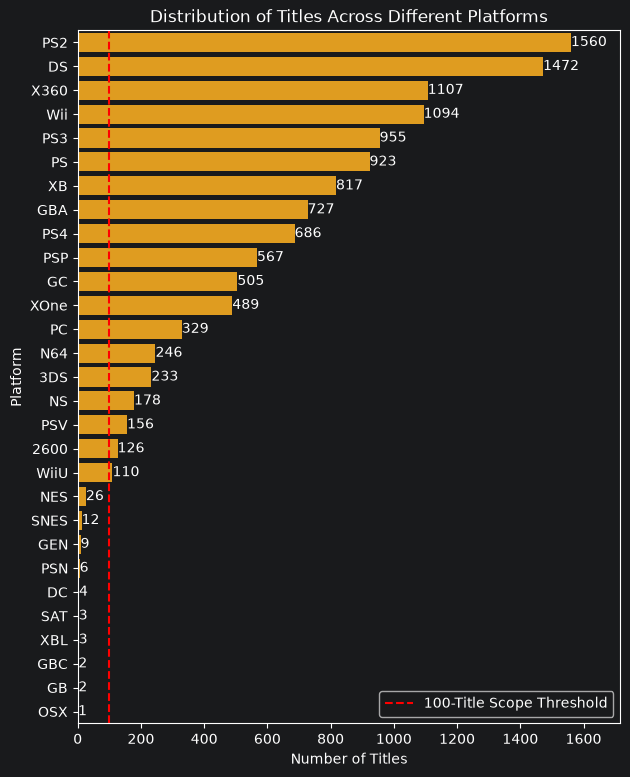

In [5]:
platform_counts = df["Platform"].value_counts()
countplot_order = platform_counts.index

plt.figure(figsize=(7,9))
ax = sns.countplot(df, y="Platform", color="orange", order=countplot_order)
bars= ax.containers[0]
ax.bar_label(bars)
plt.axvline(x=100, color="red", label="100-Title Scope Threshold", linestyle="--")
plt.xlabel("Number of Titles")
plt.xlim(0, platform_counts.max() * 1.1)
plt.ylabel("Platform")
plt.title("Distribution of Titles Across Different Platforms")
plt.legend()
plt.show()

**What it shows:** The PS2 has the most titles, with 1,560, while the Wii U has the fewest of the platforms within our research question's scope, with just 110. Ten platforms fall below the 100-title threshold that our research question requires. The titles are not spread evenly at all, with the number of titles dropping significantly after the top 2.

**What it does not show:** This plot does not necessarily show that a platform with 1,560 tracked titles sells more games per title than a platform with only 110 games.

**Principle check:** Context. I added a reference line at 100 titles so readers can immediately see which platforms meet our scope.

## B2: How are critic scores distributed among the in-scope titles, and how many titles have a score at all?
This will determine whether Critic_Score could serve as a control variable alongside genre and platform, or whether it is too incomplete to use.

> **Variables:** Critic_Score (Quantitative Continuous)

A histogram instead of a KDE, because I want to see spikes, gaps, or values stacked at round numbers that a smoothed density curve would hide.

In [6]:
total = len(df)
scored = df["Critic_Score"].notna().sum()
print(f"Titles with a critic score: {scored} of {total} -> {scored / total:.1%}\n")

print(df["Critic_Score"].describe())

min_score = df["Critic_Score"].min()
print(f"\nTitles at a minimum score of {min_score}: {(df['Critic_Score'] == min_score).sum()}")

Titles with a critic score: 3674 of 12348 -> 29.8%

count    3674.000000
mean        7.081410
std         1.432583
min         1.000000
25%         6.300000
50%         7.300000
75%         8.100000
max        10.000000
Name: Critic_Score, dtype: float64

Titles at a minimum score of 1.0: 1


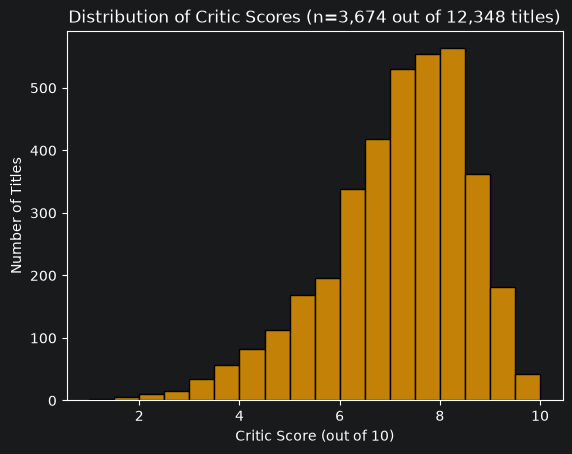

In [7]:
sns.histplot(df["Critic_Score"], color="orange", binwidth=0.5)
plt.xlabel("Critic Score (out of 10)")
plt.ylabel("Number of Titles")
plt.title("Distribution of Critic Scores (n=3,674 out of 12,348 titles)")
plt.show()

**What it shows:** Only 3,674 out of 12,348 titles (29.8%) have a critic score. On a scale out of 10, scores have a median and mean of 7.3 and 7.08 respectively, with the middle 50% falling between 6.3 and 8.1. The mean sitting below the median reflects a left skew, with a peak in the 8.0-8.5 bin and a tail going to the left. I do not think critic score can be used as a control variable since only 29.8% of the titles have scores.

**What it does not show:** This plot does not show if there is a correlation between higher scores and higher sales.

**Principle check:** Scale. I compared bin widths of 0.25, 0.5 and 1.0 and kept 0.5. Because scores are recorded to one decimal place, 0.25 bins held an uneven number of score values and produced false spikes and gaps, while 1.0 merged the peak into a few wide blocks; at 0.5 every bin holds the same number of possible scores.

## B3: Among platforms with at least 100 tracked titles, does North America sales per title differ by platform enough that it could help predict NA_Sales?
This tests half of our research question directly.

> **Variables:** NA_Sales (Quantitative Continuous) across Platform (Qualitative Nominal)

Horizontal box plots sorted by median, instead of violins, because with this many platforms the violin shapes would crowd each other, while boxes still allow a clean comparison of medians and spread.

**Filtered view for B3:** Because Plot B1 shows that several platforms fall outside the scope of our research question, B3 uses only platforms with at least 100 titles, so that no box is based on too few games to compare fairly.

In [8]:
in_scope = platform_counts[platform_counts >= 100].index

b3_df = df[df["Platform"].isin(in_scope)]

print(f"Rows before: {len(df)}, after: {len(b3_df)}. Total number of rows removed: {len(df) - len(b3_df)}")
print(f"Platforms before: {df['Platform'].nunique()}, after: {b3_df['Platform'].nunique()}")


Rows before: 12348, after: 12280. Total number of rows removed: 68
Platforms before: 29, after: 19


In [9]:
zero_sales = (b3_df["NA_Sales"] == 0).sum()
missing_sales = b3_df["NA_Sales"].isna().sum()
min_sales = b3_df["NA_Sales"].min()

print(f"Titles with zero NA sales: {zero_sales}")
print(f"Titles with missing NA sales: {missing_sales}")
print(f"Lowest NA sales value: {min_sales}")

Titles with zero NA sales: 0
Titles with missing NA sales: 0
Lowest NA sales value: 0.01


In [10]:
sales_median = b3_df["NA_Sales"].groupby(b3_df["Platform"]).median().sort_values(ascending=False)
boxplot_order = sales_median.index
print(f"Median sales value in millions of units.\n{sales_median}")

Median sales value in millions of units.
Platform
2600    0.420
X360    0.190
N64     0.180
PS3     0.180
Wii     0.140
PS2     0.130
WiiU    0.125
PS      0.120
3DS     0.100
DS      0.100
GBA     0.100
XB      0.100
PSP     0.100
GC      0.100
XOne    0.090
PS4     0.080
NS      0.050
PSV     0.045
PC      0.040
Name: NA_Sales, dtype: float64


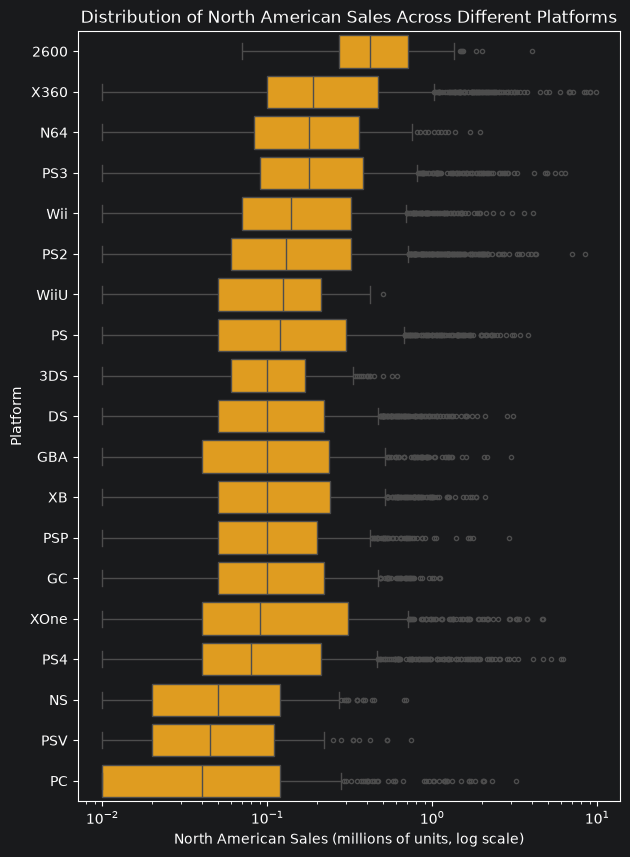

In [11]:
plt.figure(figsize=(7,10))
sns.boxplot(b3_df, x="NA_Sales", y="Platform", orient="h", color="orange", order=boxplot_order, fliersize=3)
plt.xscale("log")
plt.xlabel("North American Sales (millions of units, log scale)")
plt.ylabel("Platform")
plt.title("Distribution of North American Sales Across Different Platforms")
plt.show()

**What it shows:** Using only the 19 in-scope platforms, median North American sales range from 0.42 million for the 2600 to 0.04 million for PC, so the 2600's median is about 10 times higher. Without the 2600, the range goes from 0.04 million (PC) to 0.19 million (X360), which is only about 4.75 times higher. This means the 2600 alone accounts for most of the gap, and the other 18 platforms are much closer together. This answers our question: North American sales per title do not differ much between platforms.

**What it does not show:** The number of titles behind each box is not visible. A box built from 110 titles (Wii U) looks just as solid as one built from 1,560 (PS2).

**Principle check:** Scale. I switched to a log x-axis because on the linear axis the boxes were flattened against zero; the log axis shows each platform's spread.

## B4: For titles released through 2024, has North America sales per title shifted over time?
If it has, release era could be confounding the platform differences in Figure B3, since each platform belongs to a specific era.

> **Variables:** Release year (Quantitative Discrete) and NA_Sales (Quantitative Continuous)

A hex plot instead of a scatter plot, because with over 12,000 titles the scatter turned into a solid block even with jitter and transparency, hiding where titles concentrate. Coloring each hexagon by its title count shows that density directly, and a log y-axis keeps the many low-selling titles from being crushed by a few blockbusters.

In [12]:
release_year = pd.to_datetime(df["Release_Date"], format="%m/%d/%Y").dt.year

titles_year = release_year.value_counts().sort_index()
median_year = df["NA_Sales"].groupby(release_year).median()

titles_median = pd.DataFrame({
    "Titles": titles_year,
    "Median NA Sales (millions of units)": median_year
}).rename_axis("Release Year")

print("Titles and median North American sales per release year:\n", titles_median)

Titles and median North American sales per release year:
               Titles  Median NA Sales (millions of units)
Release Year                                             
1977.0             3                                0.910
1978.0             7                                0.350
1979.0             1                                0.290
1980.0             5                                0.440
1981.0             6                                0.725
1982.0            44                                0.435
1983.0            37                                0.500
1984.0             9                                0.430
1985.0             2                                0.420
1986.0             4                                0.370
1987.0             5                                0.450
1988.0             8                                0.370
1989.0             5                                0.220
1990.0             6                                0.290
1991.0        

Titles plotted: 12339 of 12348
Titles missing a year or NA sales: 9


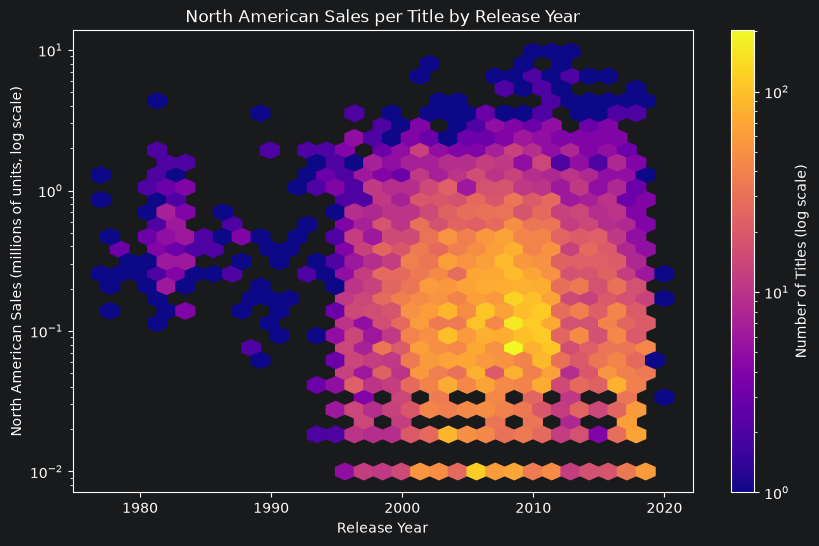

In [13]:
has_both =  release_year.notna() & df["NA_Sales"].notna()
print(f"Titles plotted: {has_both.sum()} of {len(df)}\nTitles missing a year or NA sales: {len(df) - has_both.sum()}")

plt.figure(figsize=(10,6))
hb = plt.hexbin(release_year[has_both], df["NA_Sales"][has_both], gridsize=30, yscale="log", bins="log", cmap="plasma", mincnt=1)

cb = plt.colorbar(hb)
cb.set_label("Number of Titles (log scale)")
plt.xlabel("Release Year")
plt.ylabel("North American Sales (millions of units, log scale)")
plt.title("North American Sales per Title by Release Year")
plt.show()

**What it shows:** Before 1995, only a handful of games were tracked (1 to 44 titles), but their medians were extremely high, ranging from about 0.21 to 1.02 million; in my opinion this is selection bias, since years later only the biggest hits were recorded. From 1995 to 2015, the number of tracked titles varies a lot (from 51 in 1995 to 1,070 in 2009), but the median stays about the same, between 0.09 and 0.19 million. After 2015 the median decreases (0.08 in 2016, 0.06 in 2017, and 0.05 in 2018), there are no tracked titles for 2019, and only 4 titles for 2020.

**What it does not show:** The graph does not show which platform each title belongs to, so it cannot tell whether the platform differences in B3 are really era differences.

**Principle check:** Perception. I switched from a jittered scatter plot to a hex plot, because even with jitter and transparency the scatter plot hid where the concentration really happened.


| Figure | Member | Slot | Variables | Question it answers | Principle checked |
|--------|--------|------|-----------|---------------------|-------------------|
| A1 | Aaron | 1 | … | … | … |
| A2 | Aaron | 2 | … | … | … |
| A3 | Aaron | 3 | … | … | … |
| A4 | Aaron | 4 | … | … | … |
| B1 | Sergio | 1 | Platform (title count) | How evenly are titles across platforms? | Context |
| B2 | Sergio | 2 | NA_Sales | How are critic scores distributed, and how many titles have one? | Scale |
| B3 | Sergio | 3 | Platform × NA_Sales | Do NA sales per title differ by platform? | Scale |
| B4 | Sergio | 4 | Release year × NA_Sales | Have NA sales per title shifted over the years? | Perception |

# Part 2: Lie Detector
## The Swap

### Aaron

### Sergio

## Both Plots, Fixed

## MB: MISLEADING ON PURPOSE

### Title for Title, Sega Genesis Outsells Xbox 360

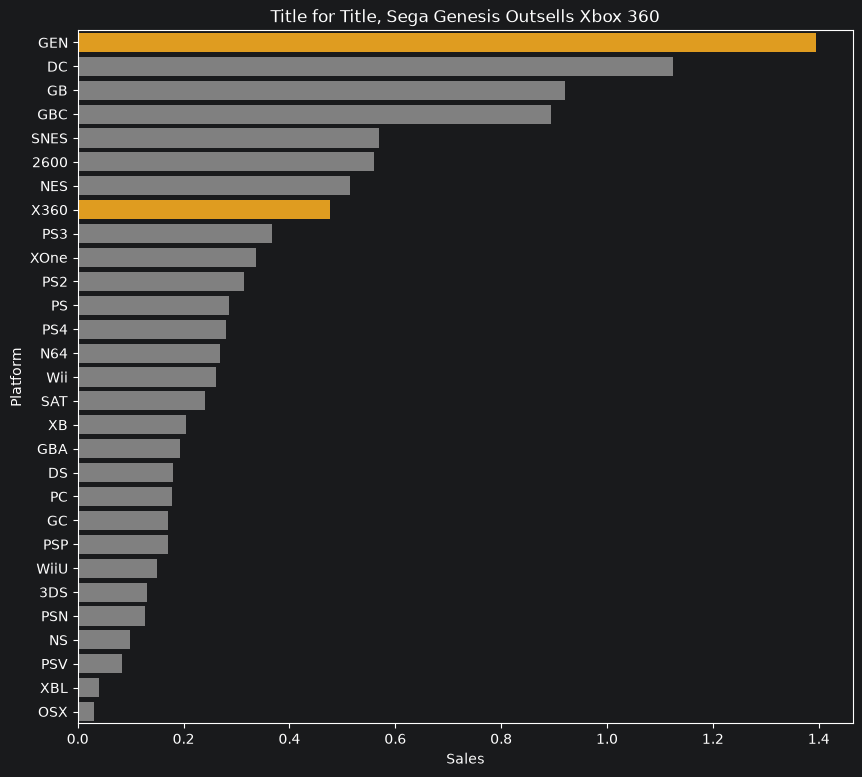

In [12]:
platform_stats = df.groupby("Platform")["NA_Sales"].agg(["mean", "count"]).sort_values("mean", ascending=False)
# Color palette
colors = {i: ("orange" if i in ["GEN", "X360"] else "gray" ) for i in platform_stats.index}

plt.figure(figsize=(10,9))
sns.barplot(x=platform_stats["mean"], y=platform_stats.index, hue=platform_stats.index, palette=colors, legend=False, errorbar=None)
plt.xlabel("Sales")
plt.ylabel("Platform")
plt.title("Title for Title, Sega Genesis Outsells Xbox 360")
plt.show()

## 2B: The Honest Plot

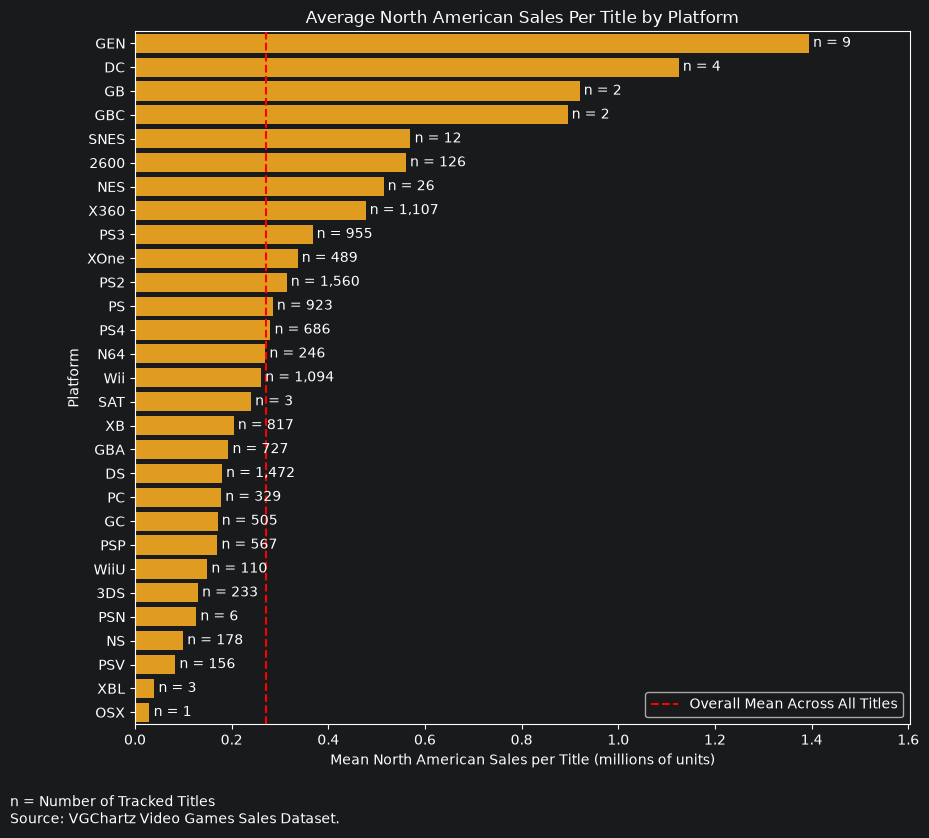

In [13]:
sales_mean = df["NA_Sales"].mean()

plt.figure(figsize=(10,9))
ax = sns.barplot(x=platform_stats["mean"], y=platform_stats.index, color="orange", errorbar=None)

labels = [f"n = {n:,}" for n in platform_stats["count"]]
ax.bar_label(ax.containers[0], labels=labels, padding=3)

plt.axvline(x=sales_mean, color="red", label="Overall Mean Across All Titles", linestyle="--", zorder=1)
plt.xlim(0, platform_stats["mean"].max() * 1.15)
plt.xlabel("Mean North American Sales per Title (millions of units)")
plt.ylabel("Platform")
plt.title("Average North American Sales Per Title by Platform")
plt.figtext(x=0, y=0, s="n = Number of Tracked Titles\nSource: VGChartz Video Games Sales Dataset.")
plt.legend()
plt.show()

## 2C: How the Trick Works

The principle I broke is context. In the misleading plot, the title was leading (`plt.title("Title for Title, Sega Genesis Outsells Xbox 360")`), the x-axis label was left vague on purpose (`plt.xlabel("Sales")`), and the bar labels showing each platform's sample size were left out, while an orange accent on GEN and X360 pointed the reader straight at that comparison. The reader immediately sees that the Sega Genesis has the biggest bar, and the leading title and vague "Sales" label lead them to conclude the headline is correct. The honest plot fixes the title and x-axis label to describe what is actually being measured, adds the sample size to each bar so the reader knows how many titles are behind each average, and uses one color for all platforms. The headline does survive in a narrow sense, since the Sega Genesis really does have a higher sales average, but it falls apart once you see the difference in titles tracked (9 for the Genesis versus 1,107 for the Xbox 360): older consoles have far fewer titles in the dataset, and the ones tracked appear to be their biggest hits, which pushes the average up.



## The Checklist

# Part 3: Hero Figure

# Part 4: The Model Case

# Part 5: Honest Data Story